<a href="https://colab.research.google.com/github/ja2faded/A05-pca/blob/main/jacksongayeskiA5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [26]:
from google.colab import drive
drive.mount ('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
import pickle

with open('/content/drive/MyDrive/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


#frequency of each token (one row per unique token)
token_df = pd.DataFrame(token_freq, columns=["Token" , "Count"])
print(token_df.head())

print('Unique tokens: ', len(token_df))







    Token  Count
0     new   1365
1    date   1202
2     get   1052
3  please   1022
4   enron    927
Unique tokens:  48691


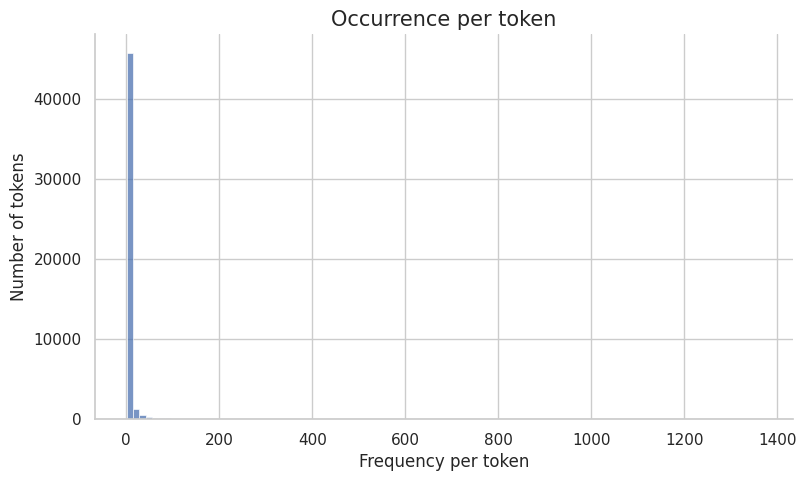

In [29]:
sns.histplot(data=token_df, x = "Count", bins=100)
plt.xlabel("Frequency per token")
plt.ylabel("Number of tokens")
plt.title("Occurrence per token")
plt.show()

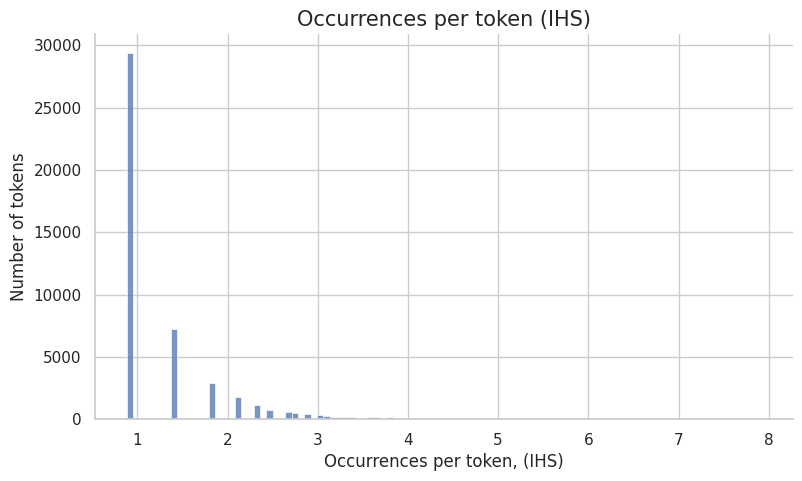

              Count     Count_ihs
count  48691.000000  48691.000000
mean       5.687889      1.439052
std       27.717476      0.958154
min        1.000000      0.881374
25%        1.000000      0.881374
50%        1.000000      0.881374
75%        2.000000      1.443635
max     1365.000000      7.912057
0.6038898359039658


In [30]:
#IHS transform-> spreads out tail (from linear model slides)
token_df["Count_ihs"] = np.arcsinh(token_df["Count"])
sns.histplot(data=token_df, x="Count_ihs", bins=100)
plt.xlabel("Occurrences per token, (IHS)")
plt.ylabel("Number of tokens")
plt.title("Occurrences per token (IHS)")
plt.show()

#stats
print(token_df.describe())
print((token_df["Count"] == 1).mean())

The distribution is very right-skewed. There are 48,691 unique tokens. 60% of unique tokens only appear once. The median is 1. The max is 1,365 and the mean is 5.69 (significantly above the median). This means most tokens are rare, while a small number of unique tokens are very frequent.

 I used the IHS since the raw histogram appeared as one bar; the IHS spreads out the tail to better see the shape.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df=pd.read_parquet('/content/drive/MyDrive/Phishing_clean.parquet')
print(df.shape)

#80/20 test split
features = df.columns.drop("Email Type")
y = df["Email Type"]
x_train, x_test, y_train, y_test = train_test_split(df[features], y , test_size=.2, random_state=100)
print("Train: ", len(x_train), "Test: ", len(x_test))



(18634, 2712)
Train:  14907 Test:  3727


In [32]:
#regression of y on the one-hot-endcoded emails
sk_fit = LinearRegression().fit(x_train, y_train)

#R^2
print("R^2 train: ", sk_fit.score(x_train, y_train))
print("R^2 test: ", sk_fit.score(x_test, y_test))

R^2 train:  0.7680301260237321
R^2 test:  0.6587519780798341


The training R^2 is 0.7680. The test R^2 is 0.6588.

In [33]:
#absolute values of coefficients
coefs = pd.Series(sk_fit.coef_, index=features)
coefs.sort_values(key=abs, ascending=False).head(15)

,0
background-image:,-0.891476
localized,0.815698
"helvetica,",0.717349
thermal,0.706216
aging,0.622411
transcript,0.578132
april's,-0.546313
retrieving,-0.527824
cnet,-0.510492
zdnet,-0.503465


The words with the largest absolute coefficient (therefore having the strongest influence on the predictions) are "background-image:" (-0.891476), "localized" (0.815698), "helvetica," (0.717349), "thermal" (0.706216), "aging" (0.622411). Positive coefficients influence the prediction towards a scam, while the negative coefficients push the prediction towards not being a scam.



**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

In [34]:
from sklearn.decomposition import PCA

x=df[features]

#drop columns with all 0s
ranges = x.max() - x.min()
x = x.loc[:, ranges > 0]

#min-max scaling
ranges = x.max() - x.min()
x_scaled=(x-x.min()) / ranges

pca_emails = PCA(n_components=2).fit(x_scaled)
x_pca = pca_emails.transform(x_scaled)

print(x_pca.shape)
print("SKlearn:", pca_emails.explained_variance_ratio_)


(18634, 2)
SKlearn: [0.01113089 0.00861136]


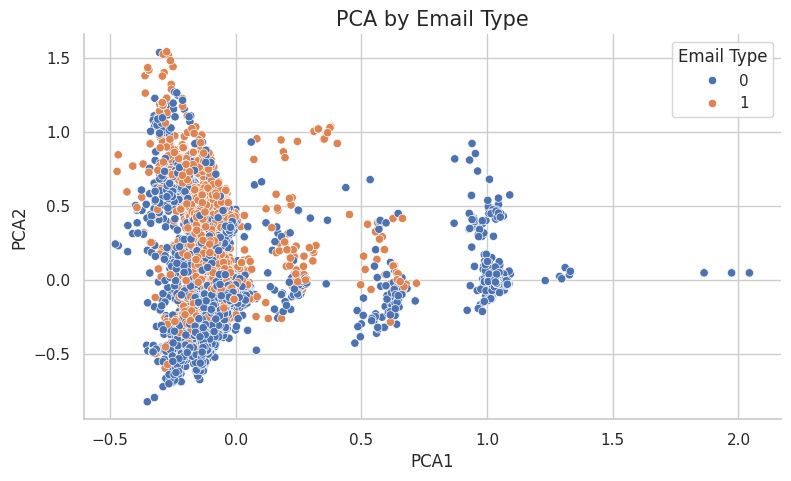

In [35]:
#scatterplot

pca_df = pd.DataFrame(x_pca, columns=['PCA1', 'PCA2'])
pca_df["Email Type"] = y.to_numpy()

sns.scatterplot(data=pca_df, x='PCA1', y='PCA2', hue='Email Type')
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.title("PCA by Email Type")
plt.show()

The scatter plot shows some separation between scam emails (1) and nonscam emails (0). In the main cluster towards the left, emails that were scams tended to have higher PC2 values than nonscam emails.

The cluster in the middle is a point of heavy overlap between the two types.

The cluster farthest to the right appears exclusively nonscam emails.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [36]:
#fit pca on training set
#using same split as question2
pca_emails_2610 = PCA(n_components=2610).fit(x_train)
x_train_pca = pca_emails_2610.transform(x_train)
x_test_pca = pca_emails_2610.transform(x_test)


sk_fit_pca = LinearRegression().fit(x_train_pca, y_train)

#R^2
print("train R^2: ", sk_fit_pca.score(x_train_pca, y_train))
print("test R^2: ", sk_fit_pca.score(x_test_pca, y_test))


train R^2:  0.7673333826623814
test R^2:  0.659709533775608


The regression had a training R^2 of 0.7673 and test R^2 of 0.6597 based on the first 2,610 principal components. These values are very similar to the findings in the linear regression in question 2: R^2 train: 0.768 and R^2 test:  0.6588. The training R^2 is slightly lower than the linear regression and the test R^2 is slightly higher (differences are very tiny though). This makes sense because 2610 components are close to the original number of columns (question 2), so the regressions are essentially working with the same data (excluding about 100 components with the least variance).

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

The advantages of using principal components to run this high-dimensional regression is that they are not correlated with one another. Many unique tokens are correlated with one another because they frequently appear together in emails. As a result, it becomes difficult for regression to figure the individual effects of tokens. Principal components avoids this issue because they have 0 covariance and are ordered based on the amount of variance they explain, resulting in dimensional reduction (can keep fewer variables while preserving the majority of the variation). This decreases the risk of overfitting because of the fewer features.

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jackson Gayeski

**Date:** 10/19/26

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 9f64263
- **AI tool and model used:** Perplexity Pro +claude Opus 5.5

### *Prompts used

1. Given the output, update the code to be more clean and concise.
2. Then, fix the graphs to be more visually appealing. List the changes in the code.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

Imports: Moved all imports into one setup block.

File paths: Used Path and one shared data-directory variable.

Naming: Used consistent names such as X_train, linear_model, and pca_2610.

Reproducibility: Kept the original train/test split seed and supplied it to PCA as well.

Repeated calculations: Reused feature ranges when removing constant columns and scaling.

PCA code: Used fit_transform() for training data instead of separate fit() and transform() calls.

Model results: Stored training and test scores in one comparison table.

Token summaries: Replaced broad descriptive output with clearly labeled statistics relevant to Q1.

Histogram layout: Placed raw and IHS-transformed histograms side by side.

Plot styling: Applied consistent fonts, colors, figure sizes, and lighter gridlines.

Coefficient display: Added a horizontal chart showing both coefficient size and sign.

PCA scatter plot: Replaced numeric legend labels with “Non-scam” and “Scam.”

Overlapping points: Used smaller markers, transparency, and no marker borders.

PCA axis labels: Included each component’s explained-variance percentage.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept  |easier to follow |
| 2 | Accept | avoids repeating file paths|
| 3 | Accept | makes it easier to distinguish regressions|
| 4 | Accept  | preserves original split |
| 5| Accept  | more concise code|
| 6 | Accept  | makes training and test easier to compare|
| 7 | Accept | improved readability |
| 8 | Accept | improved readability |
| 9 | Accept | Side-by-side histograms make the effect of the IHS transform easy to see|
| 10 | Accept | improved readability |
| 11 | Accept | improved readability |
| 12 | Accept | i“Scam”/”Non-scam” labels are clearer than 0/1 |
| 13 | Accept | improved readability |


Overall, the suggestions were accepted for readability, while the new question 5 output was scrapped since Perplexity gave a long-winded
answer that did not read very clear. I verified the answers by checking perplexity's changes against what Claude said (Claude agreed, so its output was not included).
I also verified the changes against my Part 1 suggestions to confirm there were no hallucinations.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [37]:
from pathlib import Path
from collections import Counter
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

drive.mount("/content/drive")

DATA_DIR = Path("/content/drive/MyDrive")
RANDOM_STATE = 100

sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "figure.figsize": (9, 5),
        "axes.titlesize": 15,
        "axes.labelsize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
    },
)

COLORS = {
    "Non-scam": "#0072B2",
    "Scam": "#D55E00",
}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


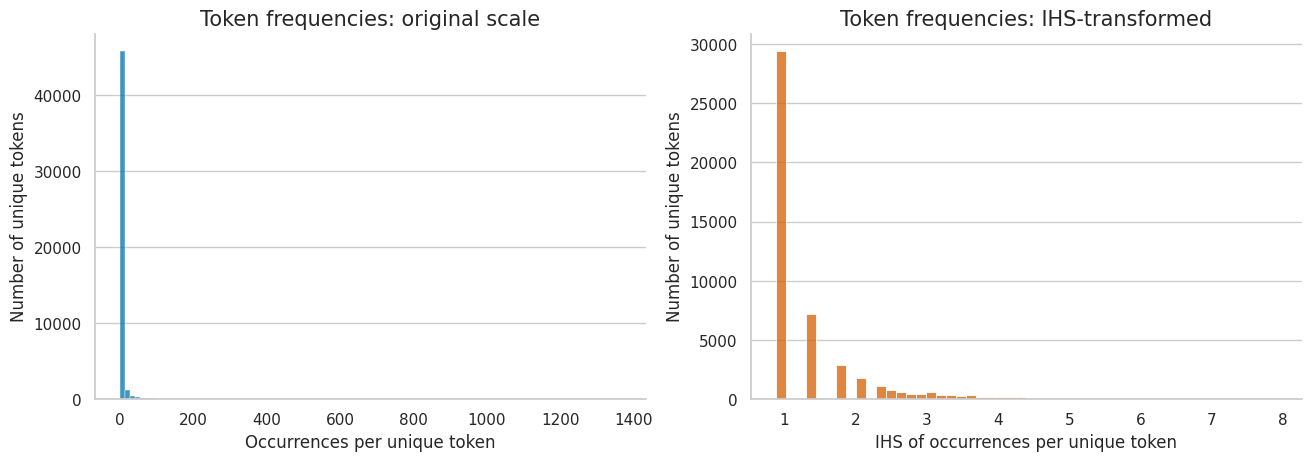

Unique tokens: 48,691
Tokens appearing once: 60.4%
Median frequency: 1
Mean frequency: 5.69
Maximum frequency: 1,365


,Token,Count,Count_IHS
0,new,1365,7.912057
1,date,1202,7.784889
2,get,1052,7.651596
3,please,1022,7.622664
4,enron,927,7.525101
5,like,923,7.520777
6,2002,869,7.460491
7,would,806,7.385231
8,one,798,7.375256
9,message,795,7.371490


In [38]:
with open(DATA_DIR / "all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_counts = Counter(all_tokens)

token_df = pd.DataFrame(
    token_counts.most_common(),
    columns=["Token", "Count"],
)

token_df["Count_IHS"] = np.arcsinh(token_df["Count"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

sns.histplot(
    data=token_df,
    x="Count",
    bins=100,
    color=COLORS["Non-scam"],
    edgecolor=None,
    ax=axes[0],
)
axes[0].set(
    title="Token frequencies: original scale",
    xlabel="Occurrences per unique token",
    ylabel="Number of unique tokens",
)

sns.histplot(
    data=token_df,
    x="Count_IHS",
    bins=50,
    color=COLORS["Scam"],
    edgecolor=None,
    ax=axes[1],
)
axes[1].set(
    title="Token frequencies: IHS-transformed",
    xlabel="IHS of occurrences per unique token",
    ylabel="Number of unique tokens",
)

for ax in axes:
    ax.grid(axis="x", visible=False)
    ax.ticklabel_format(axis="y", style="plain")

plt.show()

print(f"Unique tokens: {len(token_df):,}")
print(f"Tokens appearing once: {token_df['Count'].eq(1).mean():.1%}")
print(f"Median frequency: {token_df['Count'].median():,.0f}")
print(f"Mean frequency: {token_df['Count'].mean():,.2f}")
print(f"Maximum frequency: {token_df['Count'].max():,}")

display(token_df.head(10))

The distribution is very right-skewed. There are 48,691 unique tokens. 60% of unique tokens only appear once. The median is 1. The max is 1,365 and the mean is 5.69 (significantly above the median). This means most tokens are rare, while a small number of unique tokens are very frequent.

I used the IHS since the raw histogram appeared as one bar; the IHS spreads out the tail to better see the shape.

In [39]:
df = pd.read_parquet(DATA_DIR / "Phishing_clean.parquet")

X = df.drop(columns="Email Type")
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print(f"Dataset: {len(df):,} emails, {X.shape[1]:,} features")
print(f"Training emails: {len(X_train):,}")
print(f"Test emails: {len(X_test):,}")

linear_model = LinearRegression().fit(X_train, y_train)

results = {
    "Original features": {
        "Train R²": linear_model.score(X_train, y_train),
        "Test R²": linear_model.score(X_test, y_test),
    }
}

display(pd.DataFrame.from_dict(results, orient="index").round(4))

Dataset: 18,634 emails, 2,711 features
Training emails: 14,907
Test emails: 3,727


,Train R²,Test R²
Original features,0.768,0.6588


,Coefficient,Absolute_coefficient
background-image:,-0.8915,0.8915
localized,0.8157,0.8157
"helvetica,",0.7173,0.7173
thermal,0.7062,0.7062
aging,0.6224,0.6224
transcript,0.5781,0.5781
april's,-0.5463,0.5463
retrieving,-0.5278,0.5278
cnet,-0.5105,0.5105
zdnet,-0.5035,0.5035


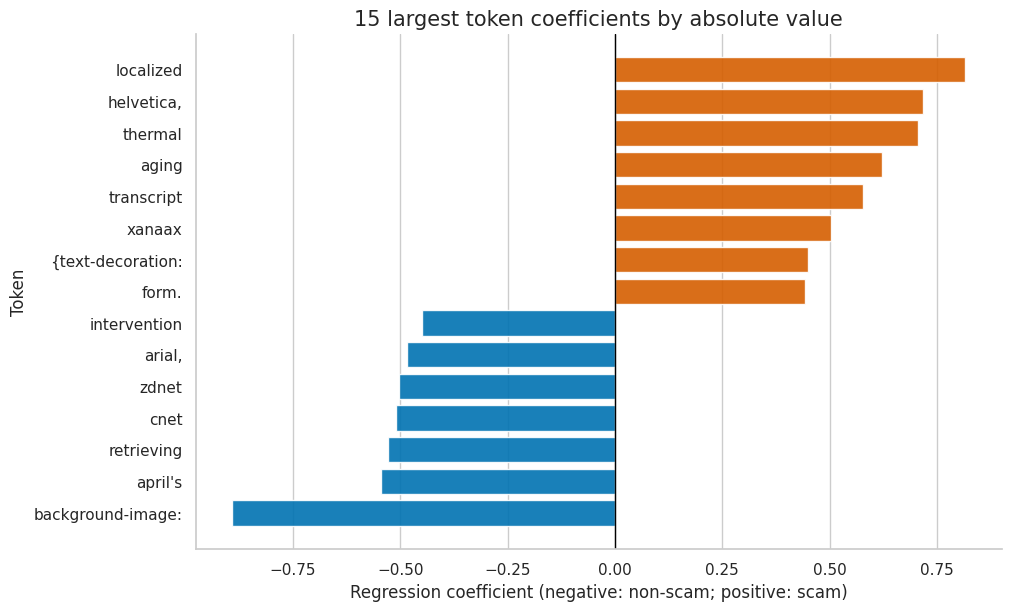

In [40]:
coefficients = pd.Series(
    linear_model.coef_,
    index=X.columns,
    name="Coefficient",
)

top_tokens = coefficients.abs().nlargest(15).index
top_coefficients = coefficients.loc[top_tokens]

display(
    top_coefficients
    .to_frame()
    .assign(Absolute_coefficient=lambda table: table["Coefficient"].abs())
    .round(4)
)

# Sort by signed value for a readable horizontal chart.
plot_coefficients = top_coefficients.sort_values()

bar_colors = [
    COLORS["Scam"] if value > 0 else COLORS["Non-scam"]
    for value in plot_coefficients
]

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

ax.barh(
    plot_coefficients.index,
    plot_coefficients.values,
    color=bar_colors,
    alpha=0.9,
)

ax.axvline(0, color="black", linewidth=1)
ax.set(
    title="15 largest token coefficients by absolute value",
    xlabel="Regression coefficient (negative: non-scam; positive: scam)",
    ylabel="Token",
)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

plt.show()

The words with the largest absolute coefficient (therefore having the strongest influence on the predictions) are "background-image:" (-0.891476), "localized" (0.815698), "helvetica," (0.717349), "thermal" (0.706216), "aging" (0.622411). Positive coefficients influence the prediction towards a scam, while the negative coefficients push the prediction towards not being a scam.

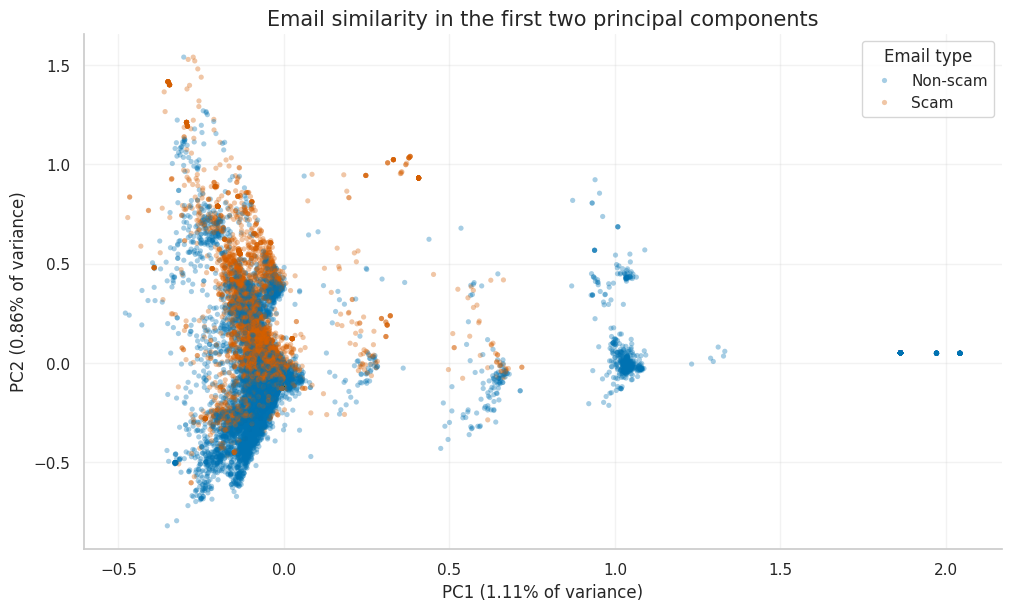

PC1 explained variance: 1.11%
PC2 explained variance: 0.86%
Combined explained variance: 1.97%


In [41]:
# Remove constant columns, then apply min–max scaling.
feature_ranges = X.max() - X.min()
X_variable = X.loc[:, feature_ranges > 0]

X_scaled = (
    (X_variable - X_variable.min())
    / feature_ranges.loc[X_variable.columns]
)

pca_2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2 = pca_2.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca_2,
    columns=["PC1", "PC2"],
    index=X.index,
)
pca_df["Email type"] = y.map({0: "Non-scam", 1: "Scam"})

variance_pct = 100 * pca_2.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Email type",
    hue_order=["Non-scam", "Scam"],
    palette=COLORS,
    s=14,
    alpha=0.35,
    linewidth=0,
    ax=ax,
)

ax.set(
    title="Email similarity in the first two principal components",
    xlabel=f"PC1 ({variance_pct[0]:.2f}% of variance)",
    ylabel=f"PC2 ({variance_pct[1]:.2f}% of variance)",
)
ax.legend(title="Email type", frameon=True)
ax.grid(alpha=0.25)

plt.show()

print(f"PC1 explained variance: {variance_pct[0]:.2f}%")
print(f"PC2 explained variance: {variance_pct[1]:.2f}%")
print(f"Combined explained variance: {variance_pct.sum():.2f}%")

The scatter plot shows some separation between scam emails (1) and nonscam emails (0). In the main cluster towards the left, emails that were scams tended to have higher PC2 values than nonscam emails.

The cluster in the middle is a point of heavy overlap between the two types.

The cluster farthest to the right appears exclusively nonscam emails.

Notably, since the features are one-hot encoded (0/1), min-max scaling does not change the data adn is included for consistency.

In [ ]:
pca_2610 = PCA(
    n_components=2610,
    random_state=RANDOM_STATE,
)

X_train_pca = pca_2610.fit_transform(X_train)
X_test_pca = pca_2610.transform(X_test)

pca_model = LinearRegression().fit(X_train_pca, y_train)

results["2,610 principal components"] = {
    "Train R²": pca_model.score(X_train_pca, y_train),
    "Test R²": pca_model.score(X_test_pca, y_test),
}

results_df = pd.DataFrame.from_dict(results, orient="index")
results_df.index.name = "Model"

display(results_df.round(4))

The advantages of using principal components to run this high-dimensional regression is that they are not correlated with one another. Many unique tokens are correlated with one another because they frequently appear together in emails. As a result, it becomes difficult for regression to figure the individual effects of tokens. Principal components avoids this issue because they have 0 covariance and are ordered based on the amount of variance they explain, resulting in dimensional reduction (can keep fewer variables while preserving the majority of the variation). This decreases the risk of overfitting because of the fewer features.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements made by the AI were readability of the code and outputs. For instance, putting the histograms next to eachother, the legend labels, variance percentages, and clean tables greatly improved the aesthetic of the assignment. The main limitation from the AI was that it was not very good at text generation and confused me when reading its suggestions. Originally, for Question 5, it suggested adding 3 paragraphs filled with incomprehensible jargon and was extremely long-winded, so I decided to just keep my response to part 1. In order to verify the outputs made by Perplexity, I cross referenced with a Claude model in order to make sure it was not hallucinating. Further, I compared its results to mine for Part 1 and confirmed its improvements. The one main remaining concern I have is that the first 2 components only explain around 2% of the variance; therefore, question 3's plot is not representative. Also I now realized that I did not need to min max scale for part 1 question 3 since the values are all 0/1.